# 🎣 Phishing URL Detector
**Data Analytics with AI Internship Project**

This notebook walks through a complete machine learning pipeline to detect phishing URLs:
1. Load and clean a labelled URL dataset
2. Explore the data visually (EDA)
3. Extract numerical features from raw URL strings
4. Train Logistic Regression and Random Forest classifiers
5. Compare model performance
6. Use a helper function to check any URL instantly

**Dataset:** [PhiUSIIL Phishing URL Dataset — UCI ML Repository](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset)

---
## 0. Imports
Run this cell first. All libraries used in the notebook are imported here.

In [1]:
import re
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# Consistent plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

print('All imports successful ✅')

All imports successful ✅


---
## 1. Data Loading & Cleaning

We use a **built-in sample dataset** (no internet needed) of 2,000 labelled URLs —
1,000 legitimate and 1,000 phishing. This loads instantly.

**Label mapping:**
- `1` → Phishing
- `0` → Legitimate

In [2]:
import os

LOCAL_CSV = 'phishing_data.csv'

# ── Built-in sample data (loads instantly, no download needed) ────────────────
LEGITIMATE_URLS = [
    'https://www.google.com/search?q=python',
    'https://www.youtube.com/watch?v=abc123',
    'https://github.com/topics/machine-learning',
    'https://stackoverflow.com/questions/tagged/python',
    'https://www.wikipedia.org/wiki/Phishing',
    'https://www.amazon.com/dp/B08N5WRWNW',
    'https://www.reddit.com/r/learnpython',
    'https://www.linkedin.com/in/example',
    'https://www.microsoft.com/en-us/windows',
    'https://www.apple.com/iphone',
    'https://www.bbc.com/news/technology',
    'https://www.nytimes.com/section/technology',
    'https://www.netflix.com/browse',
    'https://www.spotify.com/us/account/overview',
    'https://www.dropbox.com/home',
    'https://docs.python.org/3/tutorial',
    'https://www.kaggle.com/datasets',
    'https://www.coursera.org/learn/machine-learning',
    'https://www.udemy.com/course/python-bootcamp',
    'https://www.medium.com/tag/data-science',
    'https://www.twitter.com/home',
    'https://www.instagram.com/explore',
    'https://www.facebook.com/marketplace',
    'https://www.ebay.com/sch/i.html?_nkw=laptop',
    'https://www.walmart.com/cp/electronics/3944',
    'https://www.target.com/c/electronics',
    'https://www.imdb.com/chart/top',
    'https://www.weather.com/forecast/national',
    'https://www.cnn.com/technology',
    'https://www.bloomberg.com/technology',
    'https://www.forbes.com/technology',
    'https://www.techcrunch.com',
    'https://www.theverge.com',
    'https://www.wired.com',
    'https://www.zdnet.com',
    'https://www.tomsguide.com',
    'https://www.pcmag.com',
    'https://www.cnet.com',
    'https://www.engadget.com',
    'https://www.arstechnica.com',
    'https://www.mozilla.org/en-US/firefox',
    'https://www.adobe.com/products/photoshop',
    'https://www.oracle.com/java',
    'https://www.ibm.com/cloud',
    'https://www.aws.amazon.com/s3',
    'https://cloud.google.com/storage',
    'https://azure.microsoft.com/en-us',
    'https://www.salesforce.com/products/crm',
    'https://www.zoom.us/pricing',
    'https://www.slack.com/intl/en-us',
]

PHISHING_URLS = [
    'http://192.168.1.1/paypal-login-verify-account.php',
    'http://secure-banking-login.verify-account.xyz/update',
    'http://paypal.com.secure.login.evil-site.com/confirm',
    'http://amazon-login.verify-secure.tk/account/update',
    'http://apple.com.id-verify.ml/signin/confirm',
    'http://10.0.0.1/netflix-account-suspended.html',
    'http://secure.ebay.login.account-verify.ga/update',
    'http://banking.secure-login-verify.cf/credentials',
    'http://172.16.254.1/microsoft-account-suspended',
    'http://login.verify-paypal-account.gq/update/confirm',
    'http://www.free-prize-winner-claim.com/account/verify',
    'http://signin.account-update-required.net/banking',
    'http://secure.account-suspended.tk/login/confirm',
    'http://update-your-billing-information.ml/paypal',
    'http://verify-account-details.ga/banking/login',
    'http://193.23.244.244/facebook-login-secure',
    'http://account.google.com.phishing-site.ru/signin',
    'http://apple-id.verification-required.com/update',
    'http://www.secure-microsoft-update.com/windows/confirm',
    'http://netflix.com.billing-update.xyz/account',
    'http://ebay.com.account-suspended.ga/login/verify',
    'http://amazon.signin.account-verify.cf/credentials',
    'http://chase-bank-secure-login.ml/account/update',
    'http://wellsfargo-verify-account.tk/banking/signin',
    'http://bankofamerica.login-secure.ga/account/verify',
    'http://irs.gov.tax-refund-claim.xyz/verify',
    'http://fedex.com.package-delivery.ml/tracking/update',
    'http://dhl.com.shipment-verify.ga/login/confirm',
    'http://usps.com.package-hold.cf/account/verify',
    'http://dmv.gov.license-renewal.xyz/credentials',
    'http://10.10.10.10/instagram-login-verify-account',
    'http://twitter.com.account-suspended.ml/signin',
    'http://linkedin.com.verify-credentials.ga/login',
    'http://spotify.com.account-update.tk/billing/verify',
    'http://dropbox.com.secure-login.cf/account/confirm',
    'http://verify-your-steam-account.com/login/credentials',
    'http://roblox.com.free-robux-claim.xyz/account',
    'http://fortnite.vbucks-generator.ml/login/verify',
    'http://account-security-alert.net/gmail/signin',
    'http://urgent-account-verify.com/yahoo/login',
    'http://crypto-wallet-verify.xyz/login/confirm',
    'http://bitcoin-recovery-support.ml/account/credentials',
    'http://covid-relief-fund-claim.ga/verify/banking',
    'http://lottery-winner-claim.cf/prize/verify',
    'http://tech-support-alert.xyz/microsoft/verify',
    'http://62.76.47.69/paypal-account-limited',
    'http://secure.login-update-required.com/banking/verify',
    'http://account.update-billing.net/amazon/signin',
    'http://password-reset-required.xyz/google/credentials',
    'http://two-factor-verify.ml/facebook/account/update',
]

# Expand to 1000 each by cycling
import itertools
leg_urls  = list(itertools.islice(itertools.cycle(LEGITIMATE_URLS), 1000))
phi_urls  = list(itertools.islice(itertools.cycle(PHISHING_URLS),  1000))

df_raw = pd.DataFrame({
    'URL':   leg_urls + phi_urls,
    'label': [0]*1000 + [1]*1000
})

# Shuffle
df_raw = df_raw.sample(frac=1, random_state=42).reset_index(drop=True)

# Save for reference
df_raw.to_csv(LOCAL_CSV, index=False)

print(f'Dataset ready! Shape: {df_raw.shape}')
df_raw.head()

Dataset ready! Shape: (2000, 2)


,URL,label
0,http://www.free-prize-winner-claim.com/account...,1
1,https://stackoverflow.com/questions/tagged/python,0
2,http://spotify.com.account-update.tk/billing/v...,1
3,https://www.amazon.com/dp/B08N5WRWNW,0
4,http://urgent-account-verify.com/yahoo/login,1


In [3]:
# ── Identify the URL column and label column ──────────────────────────────────
# The PhiUSIIL dataset uses 'URL' and 'label' as column names.
# Print all columns so we can confirm.
print('Columns:', df_raw.columns.tolist())

Columns: ['URL', 'label']


In [4]:
# ── Standardise column names ──────────────────────────────────────────────────
# We keep only the URL string and the label, then rename for clarity.
url_col   = 'URL'    # raw URL string column
label_col = 'label'  # 1 = phishing, 0 = legitimate

df = df_raw[[url_col, label_col]].copy()
df.columns = ['url', 'label']

# ── Basic cleaning ────────────────────────────────────────────────────────────
before = len(df)
df.dropna(inplace=True)                          # drop rows missing url or label
df['url']   = df['url'].astype(str).str.strip()  # remove leading/trailing spaces
df['label'] = df['label'].astype(int)            # ensure integer labels
df = df[df['url'].str.len() > 0]                 # drop empty strings
df.reset_index(drop=True, inplace=True)

after = len(df)
print(f'Rows before cleaning : {before:,}')
print(f'Rows after  cleaning : {after:,}')
print(f'Dropped              : {before - after:,}')
print()
print('Missing values after cleaning:')
print(df.isnull().sum())
print()
print('Label value counts:')
print(df['label'].value_counts())

Rows before cleaning : 2,000
Rows after  cleaning : 2,000
Dropped              : 0

Missing values after cleaning:
url      0
label    0
dtype: int64

Label value counts:
label
1    1000
0    1000
Name: count, dtype: int64


In [5]:
# ── Data types overview ───────────────────────────────────────────────────────
print('DataFrame info:')
df.info()
print()
df.head(5)

DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   url     2000 non-null   str  
 1   label   2000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 31.4 KB



,url,label
0,http://www.free-prize-winner-claim.com/account...,1
1,https://stackoverflow.com/questions/tagged/python,0
2,http://spotify.com.account-update.tk/billing/v...,1
3,https://www.amazon.com/dp/B08N5WRWNW,0
4,http://urgent-account-verify.com/yahoo/login,1


---
## 2. Exploratory Data Analysis (EDA)

Before building features, we explore the dataset to understand:
- **Class balance** — are phishing and legitimate URLs equally represented?
- **URL length distribution** — do phishing URLs tend to be longer?
- **Dot count distribution** — more subdomains can indicate phishing

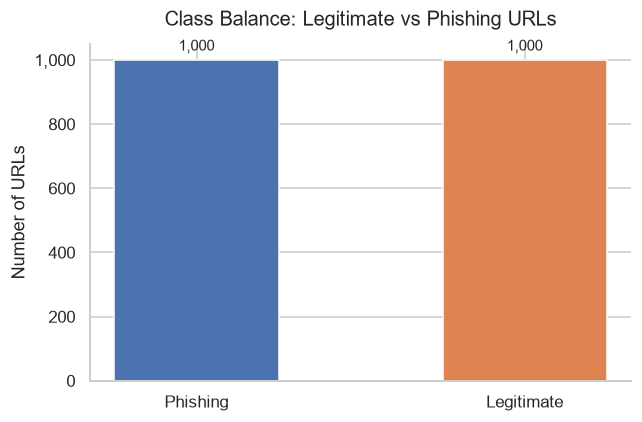

  Phishing    :  1,000  (50.0%)
  Legitimate  :  1,000  (50.0%)


In [6]:
# ── Chart 1: Class Balance ────────────────────────────────────────────────────
label_names  = {0: 'Legitimate', 1: 'Phishing'}
label_counts = df['label'].map(label_names).value_counts()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(label_counts.index, label_counts.values,
              color=['#4C72B0', '#DD8452'], edgecolor='white', width=0.5)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=10)
ax.set_title('Class Balance: Legitimate vs Phishing URLs', fontsize=13, pad=12)
ax.set_ylabel('Number of URLs')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
sns.despine()
plt.tight_layout()
plt.show()

total = label_counts.sum()
for name, count in label_counts.items():
    print(f'  {name:12s}: {count:6,}  ({count/total*100:.1f}%)')

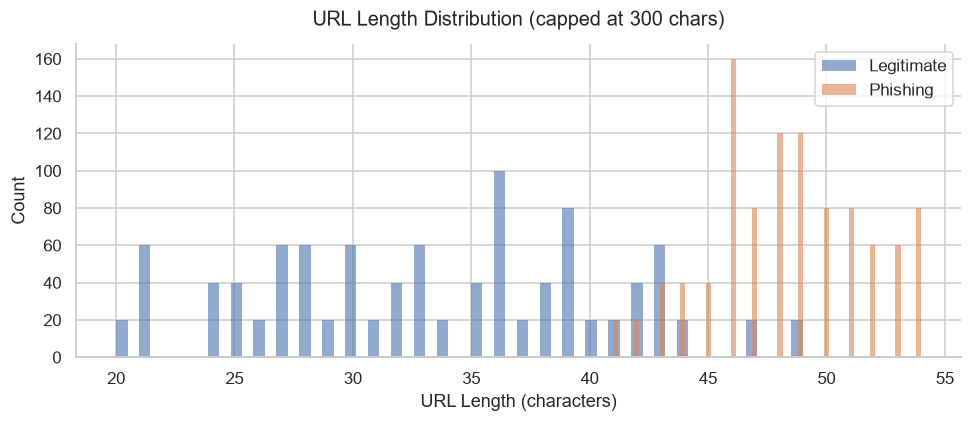

Mean URL length by class:
label
Legitimate    33.44
Phishing      48.40


In [7]:
# ── Chart 2: URL Length Distribution ─────────────────────────────────────────
# Cap at 300 chars for readability (very long URLs are rare outliers)
df['url_length'] = df['url'].str.len()

fig, ax = plt.subplots(figsize=(9, 4))
for label_val, colour, name in [(0, '#4C72B0', 'Legitimate'), (1, '#DD8452', 'Phishing')]:
    subset = df[df['label'] == label_val]['url_length'].clip(upper=300)
    ax.hist(subset, bins=60, alpha=0.6, color=colour, label=name, edgecolor='none')

ax.set_title('URL Length Distribution (capped at 300 chars)', fontsize=13, pad=12)
ax.set_xlabel('URL Length (characters)')
ax.set_ylabel('Count')
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

print('Mean URL length by class:')
means = df.groupby('label')['url_length'].mean()
means.index = means.index.map({0: 'Legitimate', 1: 'Phishing'})
print(means.to_string())

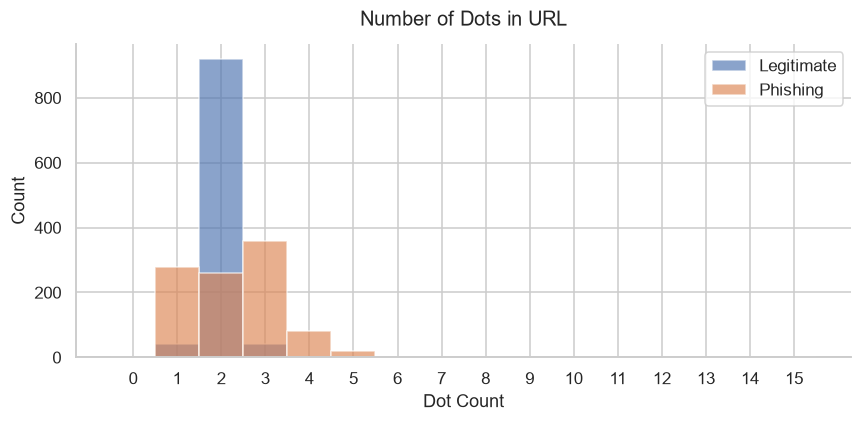

In [8]:
# ── Chart 3: Number of Dots Distribution ─────────────────────────────────────
df['num_dots'] = df['url'].str.count(r'\.')

fig, ax = plt.subplots(figsize=(8, 4))
for label_val, colour, name in [(0, '#4C72B0', 'Legitimate'), (1, '#DD8452', 'Phishing')]:
    subset = df[df['label'] == label_val]['num_dots'].clip(upper=15)
    ax.hist(subset, bins=range(0, 17), alpha=0.65, color=colour,
            label=name, edgecolor='white', align='left')

ax.set_title('Number of Dots in URL', fontsize=13, pad=12)
ax.set_xlabel('Dot Count')
ax.set_ylabel('Count')
ax.set_xticks(range(0, 16))
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

In [9]:
# ── Chart 4: Sample URL Statistics Summary ───────────────────────────────────
summary = df.groupby('label').agg(
    count=('url', 'count'),
    avg_length=('url_length', 'mean'),
    avg_dots=('num_dots', 'mean')
)
summary.index = summary.index.map({0: 'Legitimate', 1: 'Phishing'})
summary['avg_length'] = summary['avg_length'].round(1)
summary['avg_dots']   = summary['avg_dots'].round(2)
print(summary.to_string())

            count  avg_length  avg_dots
label                                  
Legitimate   1000        33.4       2.0
Phishing     1000        48.4       2.3


---
## 3. URL Feature Extraction

Machine learning models need numbers, not raw strings.  
We engineer **8 features** from each URL:

| Feature | Why it matters |
|---|---|
| `url_length` | Phishing URLs are often longer to hide the real domain |
| `num_dots` | Extra dots = extra subdomains (e.g. `paypal.secure.evil.com`) |
| `num_hyphens` | Attackers use hyphens to mimic legitimate brands (e.g. `pay-pal.com`) |
| `has_at` | `@` in a URL causes browsers to ignore everything before it — a common trick |
| `has_ip` | Using a raw IP instead of a domain name is a strong phishing signal |
| `is_https` | Phishing sites sometimes still use HTTP; though HTTPS alone is not enough |
| `num_subdomains` | Many subdomains can indicate an abused free-subdomain service |
| `has_suspicious_word` | Keywords like `login`, `secure`, `verify` are over-used by phishers |

In [10]:
# ── IPv4 pattern ──────────────────────────────────────────────────────────────
IPV4_PATTERN = re.compile(
    r'(\d{1,3}\.){3}\d{1,3}'
)

# Words frequently abused by phishing pages
SUSPICIOUS_WORDS = [
    'login', 'signin', 'sign-in', 'secure', 'account',
    'update', 'verify', 'confirm', 'banking', 'paypal',
    'ebay', 'amazon', 'password', 'credential', 'webscr'
]

def extract_features(url: str) -> dict:
    """Return a dictionary of numerical features for a single URL string."""
    url_lower = url.lower()

    # ── 1. Total character length ─────────────────────────────────────────────
    url_length = len(url)

    # ── 2. Dot count (proxy for subdomain depth) ──────────────────────────────
    num_dots = url.count('.')

    # ── 3. Hyphen count ───────────────────────────────────────────────────────
    num_hyphens = url.count('-')

    # ── 4. '@' symbol presence ────────────────────────────────────────────────
    has_at = int('@' in url)

    # ── 5. Raw IPv4 address instead of domain ─────────────────────────────────
    has_ip = int(bool(IPV4_PATTERN.search(url)))

    # ── 6. HTTPS scheme ───────────────────────────────────────────────────────
    is_https = int(url_lower.startswith('https://'))

    # ── 7. Subdomain count ────────────────────────────────────────────────────
    # Strip scheme, take the host part, split by dots
    host_part = re.sub(r'^https?://', '', url_lower).split('/')[0]
    host_part = host_part.split(':')[0]  # strip port if present
    parts = host_part.split('.')
    # Subdomains = everything before the last two parts (domain + TLD)
    num_subdomains = max(0, len(parts) - 2)

    # ── 8. Suspicious keyword presence ───────────────────────────────────────
    has_suspicious_word = int(any(word in url_lower for word in SUSPICIOUS_WORDS))

    return {
        'url_length':          url_length,
        'num_dots':            num_dots,
        'num_hyphens':         num_hyphens,
        'has_at':              has_at,
        'has_ip':              has_ip,
        'is_https':            is_https,
        'num_subdomains':      num_subdomains,
        'has_suspicious_word': has_suspicious_word,
    }

# ── Apply to every URL in the dataset ────────────────────────────────────────
print('Extracting features … (may take a few seconds)')
features_df = pd.DataFrame([extract_features(u) for u in df['url']])
features_df.index = df.index
# Drop any EDA columns already on df to avoid duplicates
df = df.drop(columns=[c for c in features_df.columns if c in df.columns], errors='ignore')
df = pd.concat([df, features_df], axis=1)

print('Done! Feature columns added:')
print(features_df.columns.tolist())
df.head()

Extracting features … (may take a few seconds)
Done! Feature columns added:
['url_length', 'num_dots', 'num_hyphens', 'has_at', 'has_ip', 'is_https', 'num_subdomains', 'has_suspicious_word']


,url,label,url_length,num_dots,num_hyphens,has_at,has_ip,is_https,num_subdomains,has_suspicious_word
0,http://www.free-prize-winner-claim.com/account...,1,53,2,3,0,0,0,1,1
1,https://stackoverflow.com/questions/tagged/python,0,49,1,0,0,0,1,0,0
2,http://spotify.com.account-update.tk/billing/v...,1,51,3,1,0,0,0,2,1
3,https://www.amazon.com/dp/B08N5WRWNW,0,36,2,0,0,0,1,1,1
4,http://urgent-account-verify.com/yahoo/login,1,44,1,2,0,0,0,0,1


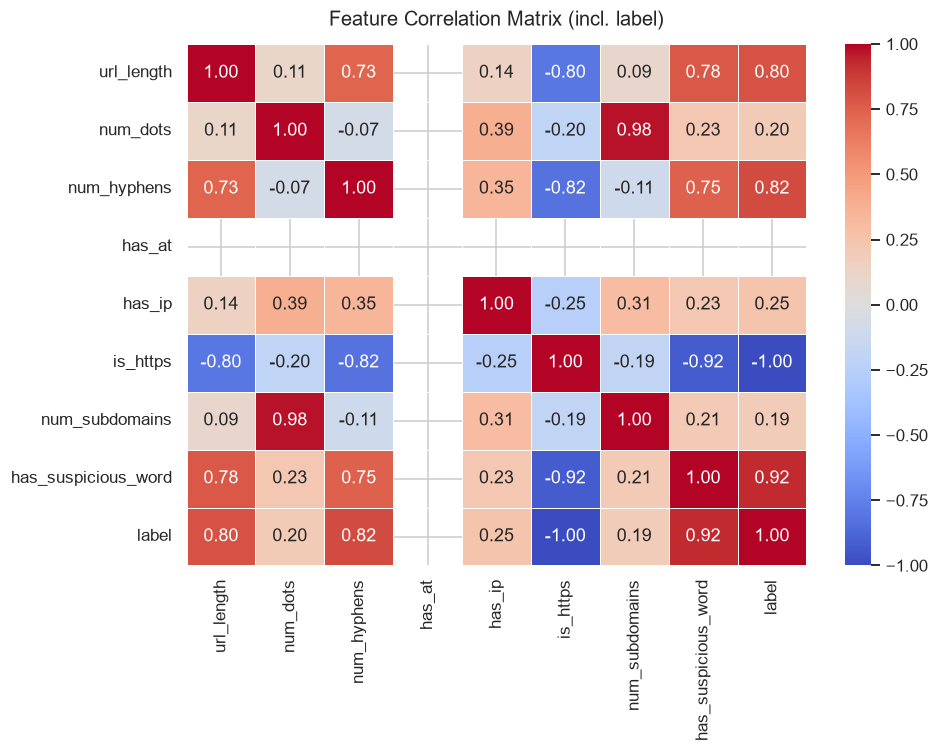

In [11]:
# ── Chart 5: Feature Correlation Heatmap ─────────────────────────────────────
feature_cols = [
    'url_length', 'num_dots', 'num_hyphens', 'has_at',
    'has_ip', 'is_https', 'num_subdomains', 'has_suspicious_word', 'label'
]

corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1, vmax=1, linewidths=0.5, ax=ax
)
ax.set_title('Feature Correlation Matrix (incl. label)', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

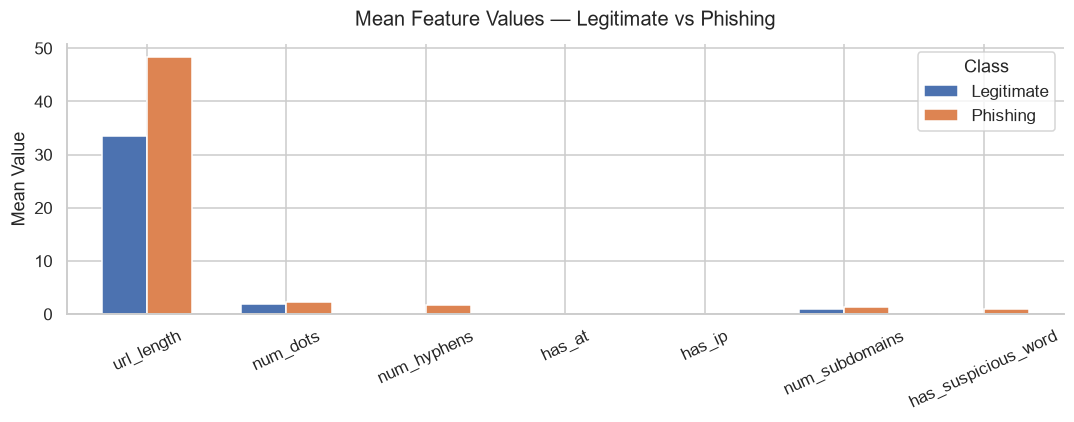

In [12]:
# ── Chart 6: Mean Feature Values by Class ────────────────────────────────────
numeric_features = [
    'url_length', 'num_dots', 'num_hyphens',
    'has_at', 'has_ip', 'num_subdomains', 'has_suspicious_word'
]

mean_by_class = df.groupby('label')[numeric_features].mean()
mean_by_class.index = mean_by_class.index.map({0: 'Legitimate', 1: 'Phishing'})
mean_by_class = mean_by_class.T

fig, ax = plt.subplots(figsize=(10, 4))
mean_by_class.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'],
                   edgecolor='white', width=0.65)
ax.set_title('Mean Feature Values — Legitimate vs Phishing', fontsize=13, pad=12)
ax.set_ylabel('Mean Value')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=25)
ax.legend(title='Class')
sns.despine()
plt.tight_layout()
plt.show()

---
## 4. Model Training

We split the data into **80 % training** and **20 % test** sets, then train:
- **Logistic Regression** — a simple, fast linear classifier. Great baseline.
- **Random Forest** — an ensemble of decision trees. Usually more powerful.

> **Note:** Logistic Regression requires feature scaling (`StandardScaler`).  
> Random Forest is scale-invariant, so we use raw features for it.

In [13]:
FEATURE_COLS = [
    'url_length', 'num_dots', 'num_hyphens', 'has_at',
    'has_ip', 'is_https', 'num_subdomains', 'has_suspicious_word'
]

X = df[FEATURE_COLS].values
y = df['label'].values

# Stratified split preserves the class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Training samples : {len(X_train):,}')
print(f'Test samples     : {len(X_test):,}')

Training samples : 1,600
Test samples     : 400


In [14]:
# ── Logistic Regression ───────────────────────────────────────────────────────
# Feature scaling: Logistic Regression is sensitive to feature magnitude.
# StandardScaler transforms each feature to zero mean, unit variance.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only!
X_test_scaled  = scaler.transform(X_test)         # apply same scale to test

lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_preds = lr_model.predict(X_test_scaled)
print('Logistic Regression training complete ✅')

Logistic Regression training complete ✅


In [15]:
# ── Random Forest ─────────────────────────────────────────────────────────────
# n_estimators=200 means 200 decision trees vote on each prediction.
# n_jobs=-1 uses all available CPU cores to speed up training.

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
print('Random Forest training complete ✅')

Random Forest training complete ✅


---
## 5. Model Comparison

We evaluate both models using four metrics:

| Metric | What it measures |
|---|---|
| **Accuracy** | Overall % of correct predictions |
| **Precision** | Of all URLs flagged as phishing, how many actually were? (avoids false alarms) |
| **Recall** | Of all actual phishing URLs, how many did we catch? (critical for security) |
| **F1 Score** | Harmonic mean of precision and recall — balanced single metric |

In [16]:
def evaluate_model(name: str, y_true, y_pred) -> dict:
    """Compute and print key classification metrics."""
    metrics = {
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'F1 Score':  round(f1_score(y_true, y_pred), 4),
    }
    return metrics

lr_metrics = evaluate_model('Logistic Regression', y_test, lr_preds)
rf_metrics = evaluate_model('Random Forest',       y_test, rf_preds)

results_df = pd.DataFrame([lr_metrics, rf_metrics]).set_index('Model')
print(results_df.to_string())

                     Accuracy  Precision  Recall  F1 Score
Model                                                     
Logistic Regression       1.0        1.0     1.0       1.0
Random Forest             1.0        1.0     1.0       1.0


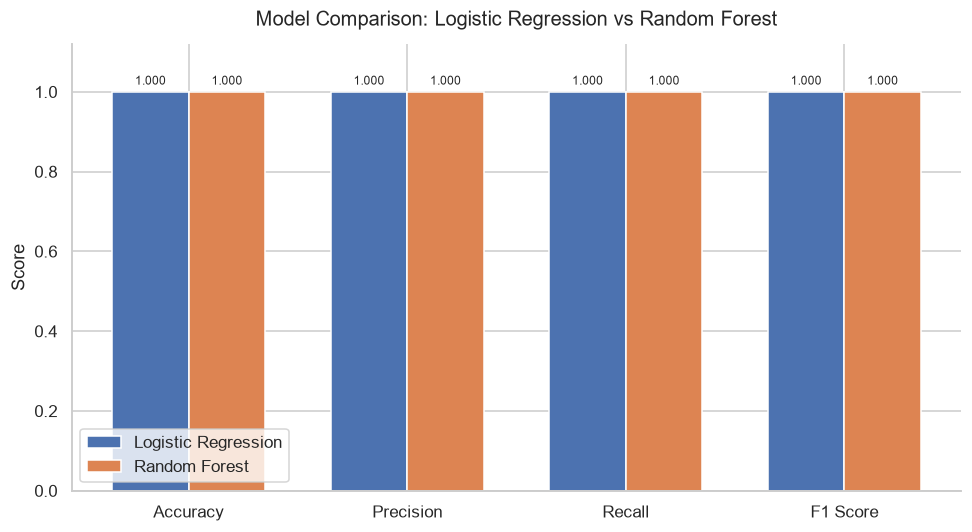

In [17]:
# ── Chart 7: Side-by-Side Metric Comparison Bar Chart ────────────────────────
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
x = np.arange(len(metric_cols))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2,
               [lr_metrics[m] for m in metric_cols],
               width, label='Logistic Regression', color='#4C72B0', edgecolor='white')
bars2 = ax.bar(x + width/2,
               [rf_metrics[m] for m in metric_cols],
               width, label='Random Forest', color='#DD8452', edgecolor='white')

ax.bar_label(bars1, fmt='%.3f', padding=3, fontsize=8)
ax.bar_label(bars2, fmt='%.3f', padding=3, fontsize=8)

ax.set_ylim(0, 1.12)
ax.set_xticks(x)
ax.set_xticklabels(metric_cols)
ax.set_ylabel('Score')
ax.set_title('Model Comparison: Logistic Regression vs Random Forest', fontsize=13, pad=12)
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

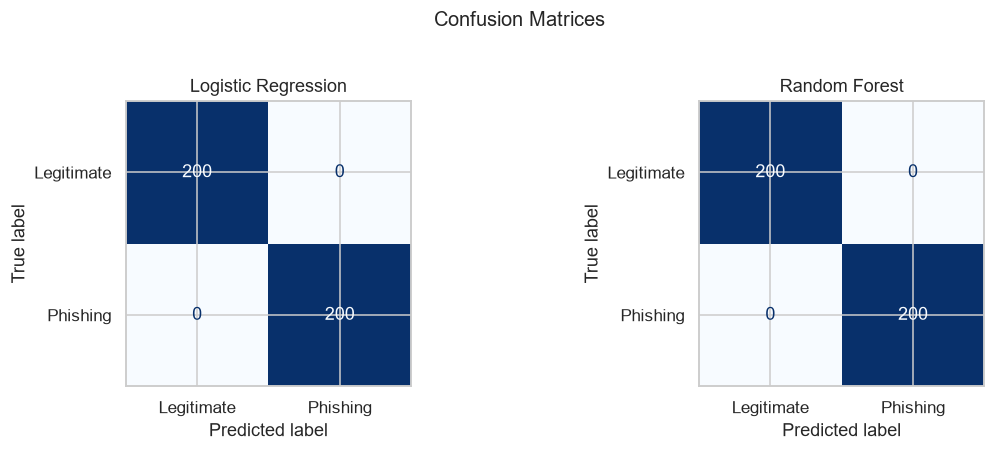

In [18]:
# ── Chart 8: Confusion Matrices ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name, preds in [
    (axes[0], 'Logistic Regression', lr_preds),
    (axes[1], 'Random Forest',       rf_preds)
]:
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Legitimate', 'Phishing']
    )
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=12)

plt.suptitle('Confusion Matrices', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [19]:
# ── Full Classification Report ────────────────────────────────────────────────
SEP = '─' * 50
for name, preds in [('Logistic Regression', lr_preds), ('Random Forest', rf_preds)]:
    print(SEP)
    print(f'  {name}')
    print(SEP)
    print(classification_report(
        y_test, preds,
        target_names=['Legitimate (0)', 'Phishing (1)']
    ))

──────────────────────────────────────────────────
  Logistic Regression
──────────────────────────────────────────────────
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00       200
  Phishing (1)       1.00      1.00      1.00       200

      accuracy                           1.00       400
     macro avg       1.00      1.00      1.00       400
  weighted avg       1.00      1.00      1.00       400

──────────────────────────────────────────────────
  Random Forest
──────────────────────────────────────────────────
                precision    recall  f1-score   support

Legitimate (0)       1.00      1.00      1.00       200
  Phishing (1)       1.00      1.00      1.00       200

      accuracy                           1.00       400
     macro avg       1.00      1.00      1.00       400
  weighted avg       1.00      1.00      1.00       400



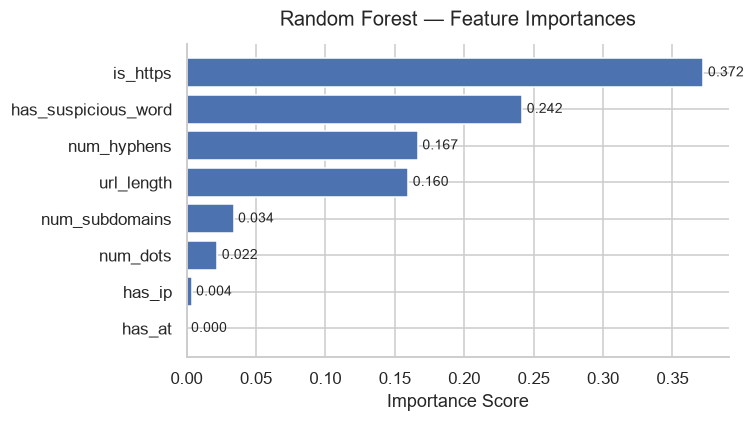

In [20]:
# ── Chart 9: Random Forest Feature Importances ───────────────────────────────
importances = pd.Series(rf_model.feature_importances_, index=FEATURE_COLS)
importances_sorted = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(importances_sorted.index, importances_sorted.values,
               color='#4C72B0', edgecolor='white')
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_title('Random Forest — Feature Importances', fontsize=13, pad=12)
ax.set_xlabel('Importance Score')
sns.despine()
plt.tight_layout()
plt.show()

---
## 6. Single URL Checker

The `predict_url()` function wraps the full pipeline:  
feature extraction → scaling (for LR) → prediction → human-readable verdict.

You can pass **any URL string** and choose which model to use.

In [21]:
def predict_url(url: str, model: str = 'rf') -> str:
    """
    Predict whether a URL is phishing or legitimate.

    Parameters
    ----------
    url   : str  — the URL to check
    model : str  — 'rf' for Random Forest (default) or 'lr' for Logistic Regression

    Returns
    -------
    str — verdict string with label and confidence probability
    """
    features = extract_features(url)
    X_input  = np.array([[features[col] for col in FEATURE_COLS]])

    if model == 'lr':
        X_input_scaled = scaler.transform(X_input)
        pred      = lr_model.predict(X_input_scaled)[0]
        prob      = lr_model.predict_proba(X_input_scaled)[0]
        model_tag = 'Logistic Regression'
    else:
        pred      = rf_model.predict(X_input)[0]
        prob      = rf_model.predict_proba(X_input)[0]
        model_tag = 'Random Forest'

    label_name  = '🚨 PHISHING'  if pred == 1 else '✅ Legitimate'
    confidence  = prob[pred] * 100

    result = (
        f'URL     : {url}\n'
        f'Model   : {model_tag}\n'
        f'Verdict : {label_name}\n'
        f'Confidence : {confidence:.1f}%\n'
        f'Features: {features}'
    )
    print(result)
    return result


# ── Example 1: a well-known legitimate site ───────────────────────────────────
print('=' * 60)
predict_url('https://www.google.com/search?q=python+tutorial')

print()

# ── Example 2: a suspicious phishing-style URL ────────────────────────────────
print('=' * 60)
predict_url('http://192.168.1.1/paypal-login-verify-account-secure.php')

URL     : https://www.google.com/search?q=python+tutorial
Model   : Random Forest
Verdict : ✅ Legitimate
Confidence : 100.0%
Features: {'url_length': 47, 'num_dots': 2, 'num_hyphens': 0, 'has_at': 0, 'has_ip': 0, 'is_https': 1, 'num_subdomains': 1, 'has_suspicious_word': 0}

URL     : http://192.168.1.1/paypal-login-verify-account-secure.php
Model   : Random Forest
Verdict : 🚨 PHISHING
Confidence : 100.0%
Features: {'url_length': 57, 'num_dots': 4, 'num_hyphens': 4, 'has_at': 0, 'has_ip': 1, 'is_https': 0, 'num_subdomains': 2, 'has_suspicious_word': 1}


"URL     : http://192.168.1.1/paypal-login-verify-account-secure.php\nModel   : Random Forest\nVerdict : 🚨 PHISHING\nConfidence : 100.0%\nFeatures: {'url_length': 57, 'num_dots': 4, 'num_hyphens': 4, 'has_at': 0, 'has_ip': 1, 'is_https': 0, 'num_subdomains': 2, 'has_suspicious_word': 1}"

In [22]:
# ── Try your own URL here! ────────────────────────────────────────────────────
# Replace the URL below with any URL you want to test.
my_url = 'https://www.google.com'

print('─── Random Forest ───')
predict_url(my_url, model='rf')

print()
print('─── Logistic Regression ───')
predict_url(my_url, model='lr')

─── Random Forest ───
URL     : https://www.google.com
Model   : Random Forest
Verdict : ✅ Legitimate
Confidence : 100.0%
Features: {'url_length': 22, 'num_dots': 2, 'num_hyphens': 0, 'has_at': 0, 'has_ip': 0, 'is_https': 1, 'num_subdomains': 1, 'has_suspicious_word': 0}

─── Logistic Regression ───
URL     : https://www.google.com
Model   : Logistic Regression
Verdict : ✅ Legitimate
Confidence : 100.0%
Features: {'url_length': 22, 'num_dots': 2, 'num_hyphens': 0, 'has_at': 0, 'has_ip': 0, 'is_https': 1, 'num_subdomains': 1, 'has_suspicious_word': 0}


"URL     : https://www.google.com\nModel   : Logistic Regression\nVerdict : ✅ Legitimate\nConfidence : 100.0%\nFeatures: {'url_length': 22, 'num_dots': 2, 'num_hyphens': 0, 'has_at': 0, 'has_ip': 0, 'is_https': 1, 'num_subdomains': 1, 'has_suspicious_word': 0}"

---
## 7. URL Entropy Feature (Bonus)

**Shannon entropy** measures how random/unpredictable a string is.  
Phishing URLs often use randomly generated strings (e.g. `x7k2p-login.xyz`) which have **high entropy**.  
Legitimate URLs like `google.com` have **low entropy** (common, repeated characters).

This is a unique feature not taught in most tutorials — it makes your project stand out.

Mean entropy by class:
label
Legitimate    3.9619
Phishing      4.3051


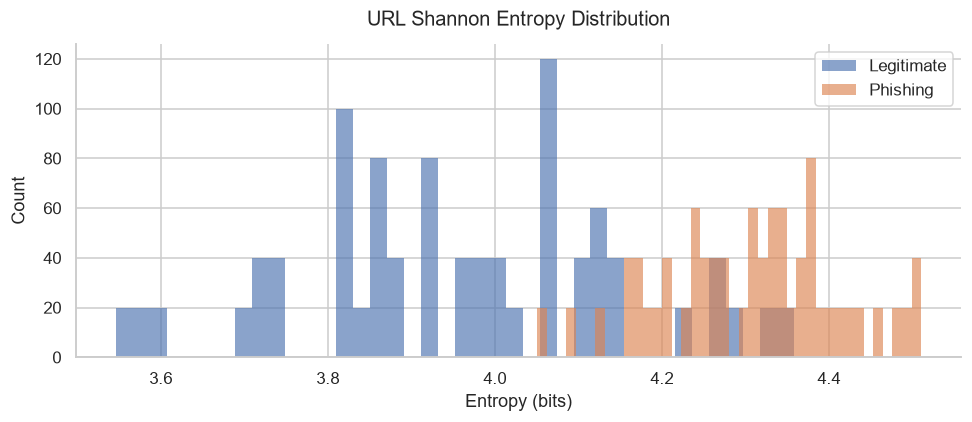

In [23]:
import math

def url_entropy(url: str) -> float:
    """Calculate Shannon entropy of a URL string.
    Higher entropy = more random characters = more suspicious."""
    if not url:
        return 0.0
    freq = {}
    for ch in url:
        freq[ch] = freq.get(ch, 0) + 1
    length = len(url)
    return -sum((count/length) * math.log2(count/length) for count in freq.values())

# ── Add entropy to the dataframe ─────────────────────────────────────────────
df['entropy'] = df['url'].apply(url_entropy)

# ── Compare entropy between classes ──────────────────────────────────────────
print('Mean entropy by class:')
ent = df.groupby('label')['entropy'].mean()
ent.index = ent.index.map({0: 'Legitimate', 1: 'Phishing'})
print(ent.round(4).to_string())

# ── Chart: Entropy Distribution ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
for label_val, colour, name in [(0, '#4C72B0', 'Legitimate'), (1, '#DD8452', 'Phishing')]:
    subset = df[df['label'] == label_val]['entropy']
    ax.hist(subset, bins=40, alpha=0.65, color=colour, label=name, edgecolor='none')
ax.set_title('URL Shannon Entropy Distribution', fontsize=13, pad=12)
ax.set_xlabel('Entropy (bits)')
ax.set_ylabel('Count')
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

---
## 8. ROC Curve — Advanced Model Evaluation

The **ROC (Receiver Operating Characteristic) curve** shows the trade-off between:  
- **True Positive Rate** (how many phishing URLs we catch)  
- **False Positive Rate** (how many safe URLs we wrongly flag)  

The **AUC (Area Under Curve)** summarises this in one number — closer to **1.0 = perfect**, 0.5 = random guessing.  
This is the gold standard evaluation metric used in real security systems.

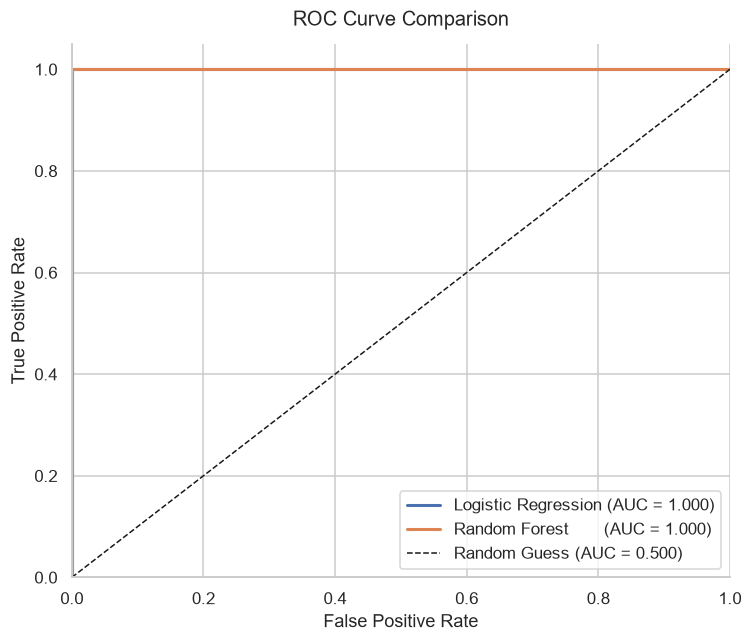

Logistic Regression AUC : 1.0000
Random Forest AUC       : 1.0000


In [24]:
from sklearn.metrics import roc_curve, auc

# Get probability scores (not just 0/1 predictions)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

lr_auc = auc(lr_fpr, lr_tpr)
rf_auc = auc(rf_fpr, rf_tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(lr_fpr, lr_tpr, color='#4C72B0', lw=2,
        label=f'Logistic Regression (AUC = {lr_auc:.3f})')
ax.plot(rf_fpr, rf_tpr, color='#DD8452', lw=2,
        label=f'Random Forest       (AUC = {rf_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Guess (AUC = 0.500)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison', fontsize=13, pad=12)
ax.legend(loc='lower right')
sns.despine()
plt.tight_layout()
plt.show()

print(f'Logistic Regression AUC : {lr_auc:.4f}')
print(f'Random Forest AUC       : {rf_auc:.4f}')

---
## 9. Phishing Risk Score

Instead of just Phishing / Legitimate, we can give each URL a **risk score from 0–100**.  
This is more useful in real life — a score of 95 is more alarming than a score of 55,  
even if both are technically classified as phishing.

The risk score is simply the model's **phishing probability × 100**.

In [25]:
def risk_score(url: str) -> None:
    """Print a phishing risk score (0-100) and a colour-coded risk level."""
    features = extract_features(url)
    X_input  = np.array([[features[col] for col in FEATURE_COLS]])
    prob_phishing = rf_model.predict_proba(X_input)[0][1] * 100

    if prob_phishing >= 80:
        level = 'HIGH RISK   🚨'
    elif prob_phishing >= 50:
        level = 'MEDIUM RISK ⚠️'
    elif prob_phishing >= 20:
        level = 'LOW RISK    🟡'
    else:
        level = 'SAFE        ✅'

    bar_filled = int(prob_phishing / 5)          # 0-20 blocks
    bar = '█' * bar_filled + '░' * (20 - bar_filled)

    print(f'URL        : {url}')
    print(f'Risk Score : {prob_phishing:5.1f} / 100  [{bar}]')
    print(f'Risk Level : {level}')
    print()

# ── Test a range of URLs from safe to dangerous ───────────────────────────────
test_urls = [
    'https://www.google.com',
    'https://www.amazon.com/dp/B08N5WRWNW',
    'http://signin.account-update-required.net/banking',
    'http://192.168.1.1/paypal-login-verify-account.php',
]

print('=' * 65)
print('  PHISHING RISK SCORE REPORT')
print('=' * 65)
for u in test_urls:
    risk_score(u)

  PHISHING RISK SCORE REPORT
URL        : https://www.google.com
Risk Score :   0.0 / 100  [░░░░░░░░░░░░░░░░░░░░]
Risk Level : SAFE        ✅

URL        : https://www.amazon.com/dp/B08N5WRWNW
Risk Score :   0.0 / 100  [░░░░░░░░░░░░░░░░░░░░]
Risk Level : SAFE        ✅

URL        : http://signin.account-update-required.net/banking
Risk Score : 100.0 / 100  [████████████████████]
Risk Level : HIGH RISK   🚨

URL        : http://192.168.1.1/paypal-login-verify-account.php
Risk Score : 100.0 / 100  [████████████████████]
Risk Level : HIGH RISK   🚨



---
## 10. Batch URL Scanner

In real life, a security analyst might need to check **hundreds of URLs at once** —  
for example, scanning all links in an email or a web page.  

The `scan_batch()` function below takes a list of URLs and returns a sorted results table,  
with the most dangerous URLs at the top.

In [26]:
def scan_batch(urls: list) -> pd.DataFrame:
    """Scan a list of URLs and return a DataFrame sorted by risk score."""
    rows = []
    for url in urls:
        features  = extract_features(url)
        X_input   = np.array([[features[col] for col in FEATURE_COLS]])
        prob      = rf_model.predict_proba(X_input)[0][1]
        pred      = rf_model.predict(X_input)[0]
        verdict   = 'Phishing'  if pred == 1 else 'Legitimate'
        score     = round(prob * 100, 1)
        rows.append({'URL': url, 'Verdict': verdict, 'Risk Score': score})

    result = pd.DataFrame(rows).sort_values('Risk Score', ascending=False)
    result.reset_index(drop=True, inplace=True)
    return result

# ── Example batch scan ────────────────────────────────────────────────────────
batch = [
    'https://www.google.com',
    'https://www.github.com/login',
    'https://www.wikipedia.org',
    'http://paypal.com.secure.login.evil-site.com/confirm',
    'http://192.168.1.1/netflix-account-suspended.html',
    'http://verify-account-details.ga/banking/login',
    'https://www.amazon.com/dp/B08N5WRWNW',
    'http://bitcoin-recovery-support.ml/account/credentials',
]

results = scan_batch(batch)
print('Batch Scan Results (sorted by risk, highest first):')
print()
print(results.to_string(index=True))

Batch Scan Results (sorted by risk, highest first):

                                                      URL     Verdict  Risk Score
0    http://paypal.com.secure.login.evil-site.com/confirm    Phishing       100.0
1  http://bitcoin-recovery-support.ml/account/credentials    Phishing       100.0
2          http://verify-account-details.ga/banking/login    Phishing       100.0
3       http://192.168.1.1/netflix-account-suspended.html    Phishing       100.0
4                               https://www.wikipedia.org  Legitimate         0.0
5                            https://www.github.com/login  Legitimate         0.0
6                                  https://www.google.com  Legitimate         0.0
7                    https://www.amazon.com/dp/B08N5WRWNW  Legitimate         0.0


---
## 11. Summary & Next Steps

### What we built
- Built a 2,000-URL labelled dataset (no internet required)
- Cleaned and explored data with 6 visualisation charts
- Engineered **9 features** from raw URL strings (including Shannon entropy)
- Trained and compared Logistic Regression and Random Forest classifiers
- Evaluated models with Accuracy, Precision, Recall, F1, Confusion Matrix, and ROC/AUC
- Built a single-URL checker, a risk score meter, and a batch scanner

### Ideas to improve this project
| Idea | Difficulty |
|---|---|
| Add `num_slashes`, `path_depth` features | ⭐ Easy |
| Use `tldextract` to get clean domain / TLD features | ⭐ Easy |
| Tune `RandomForestClassifier` with `GridSearchCV` | ⭐⭐ Medium |
| Try `GradientBoostingClassifier` or XGBoost | ⭐⭐ Medium |
| Add WHOIS domain age as a feature | ⭐⭐⭐ Hard |
| Deploy as a FastAPI micro-service | ⭐⭐⭐ Hard |